In [1]:
import pandas as pd
import tldextract
import re

extractor = tldextract.TLDExtract(suffix_list_urls=())

CORE_TERMS = ['bank', 'banking', 'account', 'payment', 'payments', 'invoice', 'billing', 'refund', 'card', 'debit', 'credit', 'credit card', 'mastercard', 'visa', 'transaction', 'transfer', 'wire', 'wallet', 'payroll', 'salary', 'statement', 'balance', 'tax', 'irs', 'ato', 'kyc', 'aml', 'swift', 'otp', 'security code', 'verification code', 'one time password', 'direct debit', 'bill', 'receipt', 'purchase', 'merchant', 'beneficiary', 'remittance', 'overdue', 'loan', 'mortgage', 'insurance', 'superannuation']
BRANDS = ['paypal', 'stripe', 'wise', 'western union', 'payoneer', 'venmo', 'cash app', 'bank of america', 'chase', 'wells fargo', 'citibank', 'hsbc', 'barclays', 'lloyds', 'natwest', 'commonwealth bank', 'commbank', 'nab', 'anz', 'westpac', 'amex', 'american express', 'mastercard', 'visa']

url_finance_keywords = list(set(CORE_TERMS + BRANDS))

def extract_url_features(url):
    url = str(url)
    ext = extractor(url)

    # Basic lexical features
    url_length = len(url)
    num_subdomains = len(ext.subdomain.split('.')) if ext.subdomain else 0
    num_special_chars = len(re.findall(r'[^a-zA-Z0-9]', url))
    has_ip = 1 if re.match(r'^https?://\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}', url) else 0
    has_at_symbol = 1 if '@' in url else 0
    num_digits = sum(c.isdigit() for c in url)
    
    keyword_hits = sum(1 for kw in url_finance_keywords if kw in url.lower())
    
    return pd.Series([url_length, num_subdomains, num_special_chars, has_ip, has_at_symbol, num_digits, keyword_hits])

url_feature_cols = [
    'url_length', 'num_subdomains', 'num_special_chars', 
    'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits'
]

print("Extracting Train URL features...")
train_df = pd.read_csv("phreshphish_train.csv", usecols=['sha256', 'url', 'label']) 
train_df[url_feature_cols] = train_df['url'].apply(extract_url_features)
train_df.to_csv("train_url_features.csv", index=False)
print(f"✅ Train shape: {train_df.shape}")

print("Extracting Test URL features...")
test_df = pd.read_csv("phreshphish_test.csv", usecols=['sha256', 'url', 'label'])
test_df[url_feature_cols] = test_df['url'].apply(extract_url_features)
test_df.to_csv("test_url_features.csv", index=False)
print(f"✅ Test shape: {test_df.shape}")

print("\n=== Preview of Extracted Features ===")
print(train_df[['url'] + url_feature_cols].head())

Extracting Train URL features...
✅ Train shape: (11543, 10)
Extracting Test URL features...
✅ Test shape: (2982, 10)

=== Preview of Extracted Features ===
                                                 url  url_length  \
0  https://forum.tunisie-foot.com/viewtopic.php?t...          52   
1  https://podcasts.apple.com/it/podcast/la-zanza...          60   
2           https://robnhod-login.gitbook.io/account          40   
3                    http://idverifychase-secure.com          31   
4              https://auth-auth--kucion.webflow.io/          37   

   num_subdomains  num_special_chars  has_ip  has_at_symbol  num_digits  \
0               1                 10       0              0           5   
1               1                 10       0              0           9   
2               1                  7       0              0           0   
3               0                  5       0              0           0   
4               1                  9       0              0 

In [2]:
import pandas as pd
from bs4 import BeautifulSoup
import re
import warnings
warnings.filterwarnings('ignore') 

def extract_html_features(html):
    if not isinstance(html, str) or len(html) == 0:
        return pd.Series([0, 0, 0, 0, 0])
    
    try:
        soup = BeautifulSoup(html, 'lxml')
    except:
        return pd.Series([0, 0, 0, 0, 0])
    
    # Check for actions
    forms = soup.find_all('form')
    has_external_form = 0
    for f in forms:
        action = str(f.get('action', '')).lower()
        if 'http' in action or '//' in action:
            has_external_form = 1
            break
            
    # Check iframes
    num_iframes = len(soup.find_all('iframe'))
    
    # Number of scripts
    num_scripts = len(soup.find_all('script'))
    
    # Title length
    title = soup.title.string if soup.title else ''
    title_length = len(title) if title else 0
    
    # Hidden content
    html_lower = html.lower()
    has_hidden_content = 1 if ('display:none' in html_lower or 'visibility:hidden' in html_lower) else 0
        
    return pd.Series([has_external_form, num_iframes, num_scripts, title_length, has_hidden_content])

html_feature_cols = ['has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']

print("Extracting Train HTML features...")
train_chunks = []
for chunk in pd.read_csv("phreshphish_train.csv", usecols=['sha256', 'html'], chunksize=500):
    chunk[html_feature_cols] = chunk['html'].apply(extract_html_features)
    train_chunks.append(chunk.drop(columns=['html'])) # after extracted, drop huge html

train_html_df = pd.concat(train_chunks, ignore_index=True)
train_html_df.to_csv("train_html_features.csv", index=False)
print(f"✅ Train shape: {train_html_df.shape}")

print("\nExtracting Train HTML features...")
test_chunks = []
for chunk in pd.read_csv("phreshphish_test.csv", usecols=['sha256', 'html'], chunksize=500):
    chunk[html_feature_cols] = chunk['html'].apply(extract_html_features)
    test_chunks.append(chunk.drop(columns=['html']))

test_html_df = pd.concat(test_chunks, ignore_index=True)
test_html_df.to_csv("test_html_features.csv", index=False)
print(f"✅ Test shape: {test_html_df.shape}")

print("\n=== Preview of Extracted HTML Features ===")
print(train_html_df.head())

Extracting Train HTML features...
✅ Train shape: (11543, 6)

Extracting Train HTML features...
✅ Test shape: (2982, 6)

=== Preview of Extracted HTML Features ===
                                              sha256  has_external_form  \
0  258da25ea9aceb0d72db0ad06c6d31fede295566494b95...                  0   
1  97758cfe72ad62bbccfc48e904e560697d8779f4028fe9...                  0   
2  4246ae8c524462ec634cd3c0c486767fe44a0ff234e94d...                  0   
3  b689d998e190b4ebcb5fbcda89ce350f8ff1a09c97498b...                  0   
4  d8d90360c2fe5b76dc2175ef4763d63116d6bd7dd2e086...                  0   

   num_iframes  num_scripts  title_length  has_hidden_content  
0            0           14            78                   0  
1            2            6            37                   1  
2            0           40            79                   0  
3            3            3             9                   0  
4            0            3            59                   0  


In [3]:
import pandas as pd

print("Merging Train datas...")
train_url = pd.read_csv("train_url_features.csv")
train_html = pd.read_csv("train_html_features.csv")

train_final = pd.merge(train_url, train_html, on="sha256", how="inner")
print(f"✅ Train merged complete. Shape: {train_final.shape}")

print("\nMerging Test datas...")
test_url = pd.read_csv("test_url_features.csv")
test_html = pd.read_csv("test_html_features.csv")

test_final = pd.merge(test_url, test_html, on="sha256", how="inner")
print(f"✅ Test merged complete. Shape: {test_final.shape}")

# Check if any merged data is missing (like some URLs not matching the HTML)
if len(train_final) != 11543 or len(test_final) != 2982:
    print("⚠️ Warning: After merging, the number of rows decreased, which means some data didn't align!")
else:
    print("✅ The rows are perfectly aligned, no data is lost!")

train_final.to_csv("train_final_features.csv", index=False)
test_final.to_csv("test_final_features.csv", index=False)

Merging Train datas...
✅ Train merged complete. Shape: (11543, 15)

Merging Test datas...
✅ Test merged complete. Shape: (2982, 15)
✅ The rows are perfectly aligned, no data is lost!


In [4]:
# preprare feature column for train model
features_to_drop = ['sha256', 'url', 'label']
X_train = train_final.drop(columns=features_to_drop)
y_train = train_final['label']

X_test = test_final.drop(columns=features_to_drop)
y_test = test_final['label']

print(f"\n🎯 The final shape of X_train: {X_train.shape} (11,543 datas, {X_train.shape[1]} features)")
print(f"🎯 The final shape of X_test: {X_test.shape}")
print("\nThe list of features is as follows:")
print(X_train.columns.tolist())


🎯 The final shape of X_train: (11543, 12) (11,543 datas, 12 features)
🎯 The final shape of X_test: (2982, 12)

The list of features is as follows:
['url_length', 'num_subdomains', 'num_special_chars', 'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits', 'has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']


In [6]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   -- ------------------------------------- 2.9/48.9 MB 11.0 MB/s eta 0:00:05
   ---- ----------------------------------- 5.0/48.9 MB 10.6 MB/s eta 0:00:05
   ----- ---------------------------------- 6.6/48.9 MB 9.6 MB/s eta 0:00:05
   ------ --------------------------------- 7.6/48.9 MB 8.3 MB/s eta 0:00:05
   ------ --------------------------------- 8.4/48.9 MB 7.5 MB/s eta 0:00:06
   ------- -------------------------------- 8.9/48.9 MB 7.1 MB/s eta 0:00:06
   ------- -------------------------------- 9.4/48.9 MB 6.0 MB/s eta 0:00:07
   ------- -------------------------------- 9.7/48.9 MB 5.8 MB/s eta 0:00:07
   -------- ------------------------------- 10.0/48.9 MB 5.4 MB/s eta 0:00:08
   -------- ------------------------------- 10.0/48.9 MB 5.4 MB/s eta 0:00:08
   -------- ------------------------------- 10.2/48.9 MB 4.4 MB/s eta 0:00:09
   -----

In [7]:
# start to train model using XGBoost
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import time

y_train_num = y_train.map({'phish': 1, 'benign': 0})
y_test_num = y_test.map({'phish': 1, 'benign': 0})

url_cols = ['url_length', 'num_subdomains', 'num_special_chars', 'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits']
html_cols = ['has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']
combined_cols = url_cols + html_cols

def train_and_evaluate(model_name, train_cols):
    print(f"\n🚀 Training and evaluating the {model_name} model...")
    
    X_tr = X_train[train_cols]
    X_te = X_test[train_cols]
    
    # initialise model parameters
    model = xgb.XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1, 
        random_state=42, eval_metric='logloss', use_label_encoder=False
    )
    
    # start training
    start = time.time()
    model.fit(X_tr, y_train_num)
    train_time = time.time() - start
    
    # predict
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    
    # return result
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test_num, y_pred),
        'Precision': precision_score(y_test_num, y_pred),
        'Recall': recall_score(y_test_num, y_pred),
        'F1-Score': f1_score(y_test_num, y_pred),
        'ROC-AUC': roc_auc_score(y_test_num, y_proba),
        'Train Time (s)': round(train_time, 2)
    }

# run three models separately
results = []
results.append(train_and_evaluate("URL-only", url_cols))
results.append(train_and_evaluate("Page-only", html_cols))
results.append(train_and_evaluate("Combined", combined_cols))

# display result
results_df = pd.DataFrame(results)
print("\n\n================ Final comparison of the three models ================")
print(results_df.to_string(index=False))


🚀 Training and evaluating the URL-only model...

🚀 Training and evaluating the Page-only model...

🚀 Training and evaluating the Combined model...


================ Final comparison of the three models ================
    Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC  Train Time (s)
 URL-only  0.842723   0.938339 0.845430  0.889465 0.930714            0.32
Page-only  0.607311   0.810053 0.620968  0.703018 0.677314            0.05
 Combined  0.894702   0.968719 0.887993  0.926601 0.929089            0.05


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import time

y_train_num = y_train.map({'phish': 1, 'benign': 0})
y_test_num = y_test.map({'phish': 1, 'benign': 0})

url_cols = ['url_length', 'num_subdomains', 'num_special_chars', 'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits']
html_cols = ['has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']
combined_cols = url_cols + html_cols

def train_and_evaluate_rf(model_name, train_cols):
    print(f"\n🌲 Training and evaluating the Random Forest {model_name} model...")
    
    X_tr = X_train[train_cols]
    X_te = X_test[train_cols]
    
    # initialise
    rf_model = RandomForestClassifier(
        n_estimators=100, 
        max_depth=10, 
        random_state=42, 
        n_jobs=-1
    )
    
    start = time.time()
    rf_model.fit(X_tr, y_train_num)
    train_time = time.time() - start
    
    y_pred = rf_model.predict(X_te)
    y_proba = rf_model.predict_proba(X_te)[:, 1]
    
    return {
        'Model': f"RF-{model_name}",
        'Accuracy': accuracy_score(y_test_num, y_pred),
        'Precision': precision_score(y_test_num, y_pred),
        'Recall': recall_score(y_test_num, y_pred),
        'F1-Score': f1_score(y_test_num, y_pred),
        'ROC-AUC': roc_auc_score(y_test_num, y_proba),
        'Train Time (s)': round(train_time, 2)
    }

rf_results = []
rf_results.append(train_and_evaluate_rf("URL-only", url_cols))
rf_results.append(train_and_evaluate_rf("Page-only", html_cols))
rf_results.append(train_and_evaluate_rf("Combined", combined_cols))

rf_results_df = pd.DataFrame(rf_results)
print("\n\n================ Comparison of three models using Random Forest ================")
print(rf_results_df.to_string(index=False))


🌲 Training and evaluating the Random Forest URL-only model...

🌲 Training and evaluating the Random Forest Page-only model...

🌲 Training and evaluating the Random Forest Combined model...


================ Comparison of three models using Random Forest ================
       Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC  Train Time (s)
 RF-URL-only  0.848759   0.935027 0.857527  0.894602 0.936179            0.15
RF-Page-only  0.616700   0.821239 0.623656  0.708938 0.685110            0.12
 RF-Combined  0.889001   0.961184 0.887545  0.922898 0.922363            0.17


In [2]:
import pandas as pd
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# fetch merged features
print("Loading feature data...")
train_final = pd.read_csv("train_final_features.csv")
test_final = pd.read_csv("test_final_features.csv")

features_to_drop = ['sha256', 'url', 'label']
X_train = train_final.drop(columns=features_to_drop)
y_train = train_final['label'].map({'phish': 1, 'benign': 0})

X_test = test_final.drop(columns=features_to_drop)
y_test = test_final['label'].map({'phish': 1, 'benign': 0})

print("Retraining the XGBoost Combined model...")
xgb_combined = xgb.XGBClassifier(
    n_estimators=100, 
    max_depth=6, 
    learning_rate=0.1, 
    random_state=42, 
    eval_metric='logloss', 
    use_label_encoder=False
)

xgb_combined.fit(X_train, y_train)
print("✅ Model recovery successful! You can continue running the SHAP code now.")

Loading feature data...
Retraining the XGBoost Combined model...
✅ Model recovery successful! You can continue running the SHAP code now.


C:\Users\PC\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:27:33] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [4]:
!pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 7.1 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [5]:
import shap
import numpy as np

print("Initialising SHAP TreeExplainer...")
explainer = shap.TreeExplainer(xgb_combined)

# collect 200 samples from test
X_test_sample = X_test.iloc[:200].copy()
y_test_sample = y_test.iloc[:200].copy()

print("Calculating SHAP values...")
shap_values = explainer.shap_values(X_test_sample)

# handing format
if isinstance(shap_values, list):
    shap_values_phish = shap_values[1] 
else:
    shap_values_phish = shap_values

def get_top_k_features(shap_row, feature_names, k=5):
    top_indices = np.argsort(np.abs(shap_row))[-k:][::-1]
    return [(feature_names[i], shap_row[i]) for i in top_indices]

print("\n=== SHAP explanations for the first 5 samples (Top-5 features)===")
for i in range(5):
    print(f"\nSamples {i}:")
    print(f"Actual Label: {y_test_sample.iloc[i]}")
    top_feats = get_top_k_features(shap_values_phish[i], X_test_sample.columns, k=5) 
    for feat_name, shap_val in top_feats:
        print(f"  - {feat_name}: {shap_val:.4f}")

Initialising SHAP TreeExplainer...
Calculating SHAP values...

=== SHAP explanations for the first 5 samples (Top-5 features)===

Samples 0:
Actual Label: 0
  - financial_keyword_hits: -1.9422
  - num_scripts: -1.3083
  - url_length: -0.4369
  - title_length: -0.4277
  - num_special_chars: -0.3494

Samples 1:
Actual Label: 1
  - financial_keyword_hits: 6.3352
  - num_scripts: 0.3983
  - has_hidden_content: 0.3061
  - num_digits: -0.2285
  - num_iframes: 0.1557

Samples 2:
Actual Label: 1
  - financial_keyword_hits: 7.9128
  - num_scripts: -0.3825
  - num_iframes: -0.2208
  - has_hidden_content: -0.1912
  - num_special_chars: -0.1684

Samples 3:
Actual Label: 1
  - title_length: 1.2337
  - financial_keyword_hits: -1.1429
  - num_special_chars: 0.9951
  - num_scripts: 0.8228
  - num_subdomains: 0.7921

Samples 4:
Actual Label: 1
  - financial_keyword_hits: -1.9069
  - num_scripts: -1.6004
  - num_iframes: -0.9252
  - num_special_chars: 0.3631
  - has_hidden_content: -0.3190


In [6]:
# now perform controlled evasion transformation for Sample 3:
target_idx = 3
original_sample = X_test.iloc[[target_idx]].copy()

print(f"=== Sample before attack {target_idx} ===")
print(f"Original predicted probability (Phishing): {xgb_combined.predict_proba(original_sample)[0][1]:.4f}")

# 🚀 Simulated attack: disguise exposed HTML quirks as a normal website
attacked_sample = original_sample.copy()
attacked_sample['title_length'] = 20      # change to a normal website length
attacked_sample['num_special_chars'] = 5  # reduce some special char
attacked_sample['num_scripts'] = 2        # reduce scripts
attacked_sample['num_subdomains'] = 1     # reduce subdomains

print(f"\n=== Sample after attack {target_idx} ===")
print(f"Predicted probability after attack (phishing): {xgb_combined.predict_proba(attacked_sample)[0][1]:.4f}")

# Recalculating the SHAP values
attacked_shap_values = explainer.shap_values(attacked_sample)
if isinstance(attacked_shap_values, list):
    attacked_shap_phish = attacked_shap_values[1]
else:
    attacked_shap_phish = attacked_shap_values

print("\n=== Top-5 SHAP explanations after the attack ===")
attacked_top_feats = get_top_k_features(attacked_shap_phish[0], attacked_sample.columns, k=5)
for feat_name, shap_val in attacked_top_feats:
    print(f"  - {feat_name}: {shap_val:.4f}")

=== Sample before attack 3 ===
Original predicted probability (Phishing): 0.9911

=== Sample after attack 3 ===
Predicted probability after attack (phishing): 0.9447

=== Top-5 SHAP explanations after the attack ===
  - num_special_chars: 1.6028
  - financial_keyword_hits: -1.1999
  - num_scripts: 1.1331
  - has_external_form: 0.6873
  - num_subdomains: -0.3192


In [7]:
# now perform controlled evasion transformation for Sample 2:
target_idx = 2
original_sample_2 = X_test.iloc[[target_idx]].copy()

print(f"=== Sample before attack {target_idx} ===")
print(f"Original predicted probability (Phishing): {xgb_combined.predict_proba(original_sample_2)[0][1]:.4f}")

# get original top-5
orig_shap = explainer.shap_values(original_sample_2)
if isinstance(orig_shap, list): orig_shap_phish = orig_shap[1]
else: orig_shap_phish = orig_shap
print("\n=== Original Top-5 SHAP explanations ===")
for feat, val in get_top_k_features(orig_shap_phish[0], original_sample_2.columns, k=5):
    print(f"  - {feat}: {val:.4f}")

# 🚀 Simulated attack: Modify HTML features (clear scripts, set hidden content to 0, reduce iframes and special characters)
attacked_sample_2 = original_sample_2.copy()
attacked_sample_2['num_scripts'] = 0
attacked_sample_2['has_hidden_content'] = 0
attacked_sample_2['num_iframes'] = 0
attacked_sample_2['num_special_chars'] = 3

print(f"\n=== Sample after attack {target_idx} ===")
print(f"Predicted probability after attack (phishing): {xgb_combined.predict_proba(attacked_sample_2)[0][1]:.4f}")

# fetch the top 5 after the attack
attacked_shap_2 = explainer.shap_values(attacked_sample_2)
if isinstance(attacked_shap_2, list): attacked_shap_2_phish = attacked_shap_2[1]
else: attacked_shap_2_phish = attacked_shap_2
print("\n=== Top-5 SHAP explanations after the attack ===")
for feat, val in get_top_k_features(attacked_shap_2_phish[0], attacked_sample_2.columns, k=5):
    print(f"  - {feat}: {val:.4f}")

=== Sample before attack 2 ===
Original predicted probability (Phishing): 0.9996

=== Original Top-5 SHAP explanations ===
  - financial_keyword_hits: 7.9128
  - num_scripts: -0.3825
  - num_iframes: -0.2208
  - has_hidden_content: -0.1912
  - num_special_chars: -0.1684

=== Sample after attack 2 ===
Predicted probability after attack (phishing): 0.9995

=== Top-5 SHAP explanations after the attack ===
  - financial_keyword_hits: 6.7091
  - num_special_chars: -1.1375
  - num_scripts: 0.5813
  - has_hidden_content: 0.2657
  - num_subdomains: -0.2149


In [1]:
import pandas as pd
import xgboost as xgb

train_final = pd.read_csv("train_final_features.csv")
test_final = pd.read_csv("test_final_features.csv")

features_to_drop = ['sha256', 'url', 'label']
X_train = train_final.drop(columns=features_to_drop)
y_train = train_final['label'].map({'phish': 1, 'benign': 0})
X_test = test_final.drop(columns=features_to_drop)
y_test = test_final['label'].map({'phish': 1, 'benign': 0})

xgb_combined = xgb.XGBClassifier(
    n_estimators=100, max_depth=6, learning_rate=0.1, 
    random_state=42, eval_metric='logloss', use_label_encoder=False
)
xgb_combined.fit(X_train, y_train)
print("✅ The environment has been successfully restored")

✅ The environment has been successfully restored


C:\Users\PC\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:58:31] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [3]:
import shap
explainer = shap.TreeExplainer(xgb_combined)

In [4]:
# now test for the 200 samples:
import numpy as np
from sklearn.metrics import jaccard_score

num_samples = 200
X_batch = X_test.iloc[:num_samples].copy()
y_batch = y_test.iloc[:num_samples].copy()

# record metrics
original_preds = []
attacked_preds = []
jaccard_similarities = []

print("Batch executing controlled evasive attacks and computing explanation stability...")

for i in range(num_samples):
    # original metrics
    orig_prob = xgb_combined.predict_proba(X_batch.iloc[[i]])[0][1]
    orig_pred = 1 if orig_prob > 0.5 else 0
    orig_shap = explainer.shap_values(X_batch.iloc[[i]])
    orig_shap_phish = orig_shap[1] if isinstance(orig_shap, list) else orig_shap
    orig_top_k_idx = np.argsort(np.abs(orig_shap_phish[0]))[-5:] # Top 5 Index
    
    # Simulated attack (randomly tamper with HTML features to mimic real evasions)
    attacked_sample = X_batch.iloc[[i]].copy()
    # Randomly reset or reduce some HTML features
    attacked_sample['num_scripts'] = np.random.randint(0, 2)
    attacked_sample['has_hidden_content'] = 0
    attacked_sample['num_iframes'] = 0
    
    # metrics after attacks
    att_prob = xgb_combined.predict_proba(attacked_sample)[0][1]
    att_pred = 1 if att_prob > 0.5 else 0
    att_shap = explainer.shap_values(attacked_sample)
    att_shap_phish = att_shap[1] if isinstance(att_shap, list) else att_shap
    att_top_k_idx = np.argsort(np.abs(att_shap_phish[0]))[-5:] # Top 5 Index after attacks
    
    # Calculate Top-5 Jaccard Similarity (feature overlap)
    # Do a binary vector calculation of Jaccard
    orig_mask = np.zeros(X_batch.shape[1])
    orig_mask[orig_top_k_idx] = 1
    att_mask = np.zeros(X_batch.shape[1])
    att_mask[att_top_k_idx] = 1
    
    jaccard = jaccard_score(orig_mask, att_mask)
    
    original_preds.append(orig_pred)
    attacked_preds.append(att_pred)
    jaccard_similarities.append(jaccard)

# === Calculate the final metric ===
original_preds = np.array(original_preds)
attacked_preds = np.array(attacked_preds)

# Attack Success Rate: originally phish (1), but after attacking became legitimate (0)
asr = np.mean((original_preds == 1) & (attacked_preds == 0))
# Average Jaccard Similarity
avg_jaccard = np.mean(jaccard_similarities)

print("\n=========================================")
print(f"🚀 Batch attack results (N={num_samples})")
print(f"Prediction Flip Rate (Attack Success Rate): {asr * 100:.2f}%")
print(f"Average Top-5 Jaccard Similarity: {avg_jaccard:.4f}")
print("=========================================")

Batch executing controlled evasive attacks and computing explanation stability...

🚀 Batch attack results (N=200)
Prediction Flip Rate (Attack Success Rate): 0.00%
Average Top-5 Jaccard Similarity: 0.6485


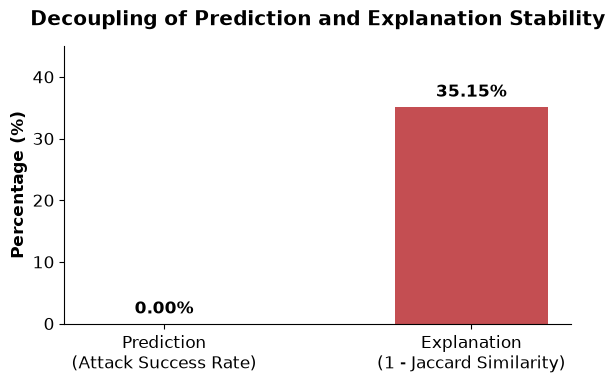

In [5]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Prediction\n(Attack Success Rate)', 'Explanation\n(1 - Jaccard Similarity)']
values = [0.00, 35.15]


plt.rcParams.update({'font.size': 12})

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(metrics, values, color=['#4C72B0', '#C44E52'], width=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, 45)
ax.set_ylabel('Percentage (%)', fontweight='bold')
ax.set_title('Decoupling of Prediction and Explanation Stability', fontweight='bold', pad=15)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('instability_chart.png', dpi=300)
plt.show()